<a href="https://colab.research.google.com/github/Krisnaaassss/explainable-heart-disease-classification-bayesian-soft-voting/blob/main/Heart_Disease_Resampling_InnerLoop_Revides.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Heart Disease Classification — Bayesian-Optimized Weighted Soft Voting
## Revised: resampling selected inside the inner loop

# 1. Setup and Configuration

In [ ]:
!pip install xgboost lightgbm imbalanced-learn scikit-optimize -q

import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import pandas as pd
import numpy as np
from collections import Counter

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (make_scorer, precision_score, recall_score, f1_score,
                             accuracy_score, roc_auc_score, balanced_accuracy_score,
                             matthews_corrcoef, confusion_matrix)
from sklearn.base import BaseEstimator, ClassifierMixin, clone

from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
import xgboost as xgb
import lightgbm as lgb

from imblearn.over_sampling import SMOTE, BorderlineSMOTE
from imblearn.combine import SMOTETomek
from imblearn.pipeline import Pipeline as ImbPipeline

from skopt import BayesSearchCV, gp_minimize
from skopt.space import Real, Integer, Categorical

print('Libraries loaded successfully.')

'pip' is not recognized as an internal or external command,
operable program or batch file.


Libraries loaded successfully.


In [ ]:
RANDOM_STATE  = 42
N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

# Jumlah iterasi Bayesian optimization
N_ITER_BASELINE = 30   # +10 dari sebelumnya karena search space kini memuat dimensi resampling
N_ITER_VOTING   = 20   # per base learner, per metode resampling
N_ITER_WEIGHTS  = 15   # gp_minimize untuk bobot voting

# [REV-B2] Satu metrik objektif untuk SEMUA tahap seleksi
#   'balanced_accuracy'  (default)  atau  'mcc'
OBJECTIVE = 'balanced_accuracy'

_OBJECTIVE_FUNCS = {
    'balanced_accuracy': balanced_accuracy_score,
    'mcc':               matthews_corrcoef,
}
_OBJECTIVE_SCORERS = {
    'balanced_accuracy': 'balanced_accuracy',
    'mcc':               make_scorer(matthews_corrcoef),
}
OBJECTIVE_FUNC   = _OBJECTIVE_FUNCS[OBJECTIVE]     # dipakai di optimasi bobot & pemilihan resampling
OBJECTIVE_SCORER = _OBJECTIVE_SCORERS[OBJECTIVE]   # dipakai di BayesSearchCV

SCORING = {
    'accuracy':     'accuracy',
    'precision':    make_scorer(precision_score, zero_division=0),
    'recall':       make_scorer(recall_score,    zero_division=0),
    'specificity':  make_scorer(recall_score,    pos_label=0, zero_division=0),
    'f1':           make_scorer(f1_score,        zero_division=0),
    'balanced_acc': 'balanced_accuracy',
    'mcc':          make_scorer(matthews_corrcoef),
    'roc_auc':      'roc_auc',
}
METRIC_KEYS = list(SCORING.keys())

RESAMPLING_METHODS = ['none', 'smote', 'borderline_smote', 'smote_tomek']

def get_resampler(resampling_method):
    if resampling_method == 'none':
        return None
    if resampling_method == 'smote':
        return SMOTE(random_state=RANDOM_STATE, k_neighbors=5)
    if resampling_method == 'borderline_smote':
        return BorderlineSMOTE(random_state=RANDOM_STATE, kind='borderline-1',
                               k_neighbors=5, m_neighbors=10)
    if resampling_method == 'smote_tomek':
        return SMOTETomek(random_state=RANDOM_STATE,
                          smote=SMOTE(random_state=RANDOM_STATE, k_neighbors=5))
    raise ValueError(f'Unknown resampling_method: {resampling_method}')

def get_resampling_label(resampling_method):
    return {'none': 'No Resampling', 'smote': 'SMOTE',
            'borderline_smote': 'Borderline-SMOTE', 'smote_tomek': 'SMOTE-Tomek',
            'auto': 'Inner-loop selection'}[resampling_method]

print(f'Global configuration completed. Objective = {OBJECTIVE}')

Global configuration completed. Objective = balanced_accuracy


## 1.1 Save / resume results to Google Drive
Setiap hasil dataset disimpan ke Drive sebagai `.pkl`. Jika sesi Colab terputus, jalankan ulang sel-sel setup lalu sel dataset: dataset yang sudah selesai langsung dimuat dari Drive, tidak dihitung ulang. Set `FORCE_RERUN = True` untuk memaksa hitung ulang.

In [ ]:
import os, pickle

try:
    from google.colab import drive
    drive.mount('/content/drive')
    RESULTS_DIR = '/content/drive/MyDrive/heart_disease_revision_results'
except ImportError:                      # bukan di Colab -> simpan lokal
    RESULTS_DIR = './heart_disease_revision_results'

RESULTS_TAG = f'{OBJECTIVE}'             # nama folder ikut objective agar hasil BA dan MCC tidak tertukar
RESULTS_PATH = os.path.join(RESULTS_DIR, RESULTS_TAG)
os.makedirs(RESULTS_PATH, exist_ok=True)

FORCE_RERUN = False

def save_summary(obj, name):
    path = os.path.join(RESULTS_PATH, f'{name}.pkl')
    with open(path, 'wb') as f:
        pickle.dump(obj, f)
    print(f'  Saved -> {path}')

def load_summary(name):
    path = os.path.join(RESULTS_PATH, f'{name}.pkl')
    with open(path, 'rb') as f:
        return pickle.load(f)

def run_or_load(name, run_fn):
    path = os.path.join(RESULTS_PATH, f'{name}.pkl')
    if os.path.exists(path) and not FORCE_RERUN:
        print(f'  Loaded from {path} (set FORCE_RERUN = True to recompute)')
        return load_summary(name)
    obj = run_fn()
    save_summary(obj, name)
    return obj

print(f'Results directory: {RESULTS_PATH}')

Results directory: ./heart_disease_revision_results\balanced_accuracy


# 2. Pipeline Definition
## 2.1 Resampler as a tunable pipeline step [REV-B1]
`ResamplerSwitch` adalah satu step pipeline dengan parameter `method`. Karena berada di dalam pipeline, `BayesSearchCV` dapat mencari `resampler__method` bersama hyperparameter model, dan resampling tetap hanya diterapkan pada inner-training fold.

In [ ]:
class ResamplerSwitch(BaseEstimator):
    def __init__(self, method='none'):
        self.method = method

    def fit_resample(self, X, y):
        sampler = get_resampler(self.method)
        if sampler is None:
            return X, y
        return sampler.fit_resample(X, y)


def _make_pipe(model, resampling_method='none'):
    # [REV-ord] imputer -> scaler -> resampler -> model
    # 'auto' : resampler bisa di-tuning (resampler__method masuk search space)
    # lainnya: resampler tetap (dipakai untuk refit akhir & analisis sensitivitas)
    method = 'none' if resampling_method == 'auto' else resampling_method
    return ImbPipeline([
        ('imputer',   SimpleImputer(strategy='median')),
        ('scaler',    StandardScaler()),
        ('resampler', ResamplerSwitch(method=method)),
        ('model',     model),
    ])

print('Pipeline initialized.')

Pipeline initialized.


## 2.2 Baseline models with Bayesian optimization

In [ ]:
def _build_models_and_spaces():
    return {
        'SVM': (
            SVC(probability=True, random_state=RANDOM_STATE),
            {'model__C':      Real(1e-2, 1e2, prior='log-uniform'),
             'model__kernel': Categorical(['rbf', 'linear'])},
        ),
        'Naive Bayes': (
            GaussianNB(),
            {'model__var_smoothing': Real(1e-10, 1e-6, prior='log-uniform')},
        ),
        'Random Forest': (
            RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
            {'model__n_estimators': Integer(50, 300),
             'model__max_depth':    Integer(3, 30)},
        ),
        'J48 (DecTree)': (
            DecisionTreeClassifier(random_state=RANDOM_STATE),
            {'model__max_depth':  Integer(2, 20),
             'model__criterion':  Categorical(['gini', 'entropy'])},
        ),
        'Logistic Regression': (
            LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
            {'model__C': Real(1e-2, 1e2, prior='log-uniform')},
        ),
        'XGBoost': (
            xgb.XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=1),
            {'model__n_estimators':  Integer(50, 300),
             'model__max_depth':     Integer(2, 10),
             'model__learning_rate': Real(1e-2, 3e-1, prior='log-uniform')},
        ),
        'LightGBM': (
            lgb.LGBMClassifier(random_state=RANDOM_STATE, verbose=-1, n_jobs=1),
            {'model__n_estimators':  Integer(50, 500),
             'model__num_leaves':    Integer(7, 150),
             'model__learning_rate': Real(1e-2, 3e-1, prior='log-uniform')},
        ),
        'KNN': (
            KNeighborsClassifier(n_jobs=1),
            {'model__n_neighbors': Integer(3, 15),
             'model__weights':     Categorical(['uniform', 'distance'])},
        ),
    }


def _search_space(space, resampling_method):
    # [REV-B1] resampling ikut dioptimasi di inner loop bila 'auto'
    if resampling_method == 'auto':
        return {**space, 'resampler__method': Categorical(RESAMPLING_METHODS)}
    return space


def _print_header(title):
    print(f'\n  {title}')
    print(f'  {"Model":<22} {"Acc":>7} {"Spec":>7} {"Rec":>7} {"F1":>7} {"BalAcc":>7} {"MCC":>7} {"AUC":>7}  Resampling (per fold)')
    print('  ' + '─' * 110)


def _print_row(name, r, methods=None):
    m = '' if methods is None else ', '.join(f'{k}×{v}' for k, v in Counter(methods).most_common())
    print(f'  {name:<22}'
          f' {r["accuracy"].mean()*100:>6.2f}%'
          f' {r["specificity"].mean()*100:>6.2f}%'
          f' {r["recall"].mean()*100:>6.2f}%'
          f' {r["f1"].mean()*100:>6.2f}%'
          f' {r["balanced_acc"].mean()*100:>6.2f}%'
          f' {r["mcc"].mean():>7.3f}'
          f' {r["roc_auc"].mean()*100:>6.2f}%  {m}')


def run_nested_cv_baseline(X, y, dataset_name='', resampling_method='auto',
                           n_bayes_iter=None):
    n_bayes_iter = n_bayes_iter or N_ITER_BASELINE
    X = X.reset_index(drop=True)
    y = pd.Series(np.asarray(y)).reset_index(drop=True)

    outer_cv = StratifiedKFold(n_splits=N_OUTER_FOLDS, shuffle=True, random_state=RANDOM_STATE)
    inner_cv = StratifiedKFold(n_splits=N_INNER_FOLDS, shuffle=True, random_state=RANDOM_STATE)

    _print_header(f'Nested 5-Fold CV — Baseline [{dataset_name}] | {get_resampling_label(resampling_method)} | objective={OBJECTIVE}')

    results = {}
    for name, (model, space) in _build_models_and_spaces().items():
        bs = BayesSearchCV(
            _make_pipe(model, resampling_method),
            search_spaces=_search_space(space, resampling_method),
            n_iter=n_bayes_iter, cv=inner_cv,
            scoring=OBJECTIVE_SCORER,          # [REV-B2]
            n_jobs=1, refit=True, random_state=RANDOM_STATE,
        )
        score = cross_validate(bs, X, y, cv=outer_cv, scoring=SCORING, n_jobs=-1,
                               return_estimator=True, return_indices=True)

        r = {k: score[f'test_{k}'] for k in METRIC_KEYS}

        # Metode resampling yang dipilih inner loop di setiap outer fold
        if resampling_method == 'auto':
            r['resampling_per_fold'] = [est.best_params_['resampler__method'] for est in score['estimator']]
        else:
            r['resampling_per_fold'] = [resampling_method] * N_OUTER_FOLDS

        # Confusion matrix dari model yang sama (tanpa melatih ulang lewat cross_val_predict)
        y_pred = np.empty(len(y), dtype=int)
        for est, te in zip(score['estimator'], score['indices']['test']):
            y_pred[te] = est.predict(X.iloc[te])
        r['confusion_matrix'] = confusion_matrix(y, y_pred)

        results[name] = r
        _print_row(name, r, r['resampling_per_fold'])

    return results

print('Baseline evaluation functions initialized.')

Baseline evaluation functions initialized.


## 2.3 Weighted Soft Voting Ensemble

In [ ]:
class WeightedSoftVoting(BaseEstimator, ClassifierMixin):

    def __init__(self, svm=None, rf=None, lgbm=None,
                 w_svm=1.0, w_rf=1.0, w_lgbm=1.0):
        self.svm = svm
        self.rf = rf
        self.lgbm = lgbm
        self.w_svm = w_svm
        self.w_rf = w_rf
        self.w_lgbm = w_lgbm

    def fit(self, X, y):
        self.svm_  = clone(self.svm).fit(X, y)
        self.rf_   = clone(self.rf).fit(X, y)
        self.lgbm_ = clone(self.lgbm).fit(X, y)
        self.classes_ = self.svm_.classes_
        return self

    def predict_proba(self, X):
        w = np.array([self.w_svm, self.w_rf, self.w_lgbm], dtype=float)
        w = w / w.sum()
        return (w[0] * self.svm_.predict_proba(X)
                + w[1] * self.rf_.predict_proba(X)
                + w[2] * self.lgbm_.predict_proba(X))

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]


def _voting_members():
    return {
        'svm': (
            SVC(probability=True, random_state=RANDOM_STATE),
            {'model__C':      Real(1e-2, 1e2, prior='log-uniform'),
             'model__kernel': Categorical(['rbf', 'linear'])},
        ),
        'rf': (
            RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
            {'model__n_estimators': Integer(50, 300),
             'model__max_depth':    Integer(3, 30)},
        ),
        'lgbm': (
            lgb.LGBMClassifier(random_state=RANDOM_STATE, verbose=-1, n_jobs=1),
            {'model__n_estimators':  Integer(50, 500),
             'model__num_leaves':    Integer(7, 150),
             'model__learning_rate': Real(1e-2, 3e-1, prior='log-uniform')},
        ),
    }


def get_best_params_for_voting(X, y, resampling_method, n_bayes_iter=None):
    # Tuning base learner untuk SATU metode resampling tetap (dipanggil per metode)
    n_bayes_iter = n_bayes_iter or N_ITER_VOTING
    inner_cv = StratifiedKFold(n_splits=N_INNER_FOLDS, shuffle=True, random_state=RANDOM_STATE)
    best_params = {}
    for key, (model, space) in _voting_members().items():
        bs = BayesSearchCV(
            _make_pipe(model, resampling_method), search_spaces=space,
            n_iter=n_bayes_iter, cv=inner_cv,
            scoring=OBJECTIVE_SCORER,           # [REV-B2]
            n_jobs=-1, refit=False, random_state=RANDOM_STATE,
        )
        bs.fit(X, y)
        best_params[key] = {k.replace('model__', ''): v for k, v in bs.best_params_.items()}
    return best_params


def _base_learners(best_params):
    return (SVC(probability=True, random_state=RANDOM_STATE, **best_params['svm']),
            RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1, **best_params['rf']),
            lgb.LGBMClassifier(random_state=RANDOM_STATE, verbose=-1, n_jobs=1, **best_params['lgbm']))


def _get_oof_base_proba(X_tr, y_tr, best_params, resampling_method, inner_cv):
    X_tr = X_tr.reset_index(drop=True)
    y_tr = pd.Series(np.asarray(y_tr)).reset_index(drop=True)
    oof = np.zeros((len(X_tr), 3))

    for in_idx, val_idx in inner_cv.split(X_tr, y_tr):
        # imputer, scaler, resampler di-fit HANYA pada inner-train fold (lewat pipeline)
        for j, base in enumerate(_base_learners(best_params)):
            pipe = _make_pipe(base, resampling_method)
            pipe.fit(X_tr.iloc[in_idx], y_tr.iloc[in_idx])
            oof[val_idx, j] = pipe.predict_proba(X_tr.iloc[val_idx])[:, 1]

    return oof[:, 0], oof[:, 1], oof[:, 2], y_tr.values


def _search_best_weights(oof_svm, oof_rf, oof_lgbm, y_true, n_calls=None):
    n_calls = n_calls or N_ITER_WEIGHTS
    space = [Real(0.1, 3.0, name='w_svm'), Real(0.1, 3.0, name='w_rf'), Real(0.1, 3.0, name='w_lgbm')]

    def objective(params):
        w = np.array(params) / np.sum(params)
        proba = w[0] * oof_svm + w[1] * oof_rf + w[2] * oof_lgbm
        pred = (proba >= 0.5).astype(int)
        return -OBJECTIVE_FUNC(y_true, pred)   # [REV-B2] metrik yang sama dengan tuning

    res = gp_minimize(objective, space, n_calls=n_calls, n_initial_points=min(5, n_calls),
                      random_state=RANDOM_STATE, verbose=False)
    return {'w_svm': res.x[0], 'w_rf': res.x[1], 'w_lgbm': res.x[2]}, -res.fun


def _fit_final_and_predict(X_tr, y_tr, X_te, best_params, best_weights, resampling_method):
    svm, rf, lgbm = _base_learners(best_params)
    voting_model = WeightedSoftVoting(svm=svm, rf=rf, lgbm=lgbm, **best_weights)
    pipe = _make_pipe(voting_model, resampling_method)
    pipe.fit(X_tr, y_tr)
    return pipe.predict(X_te), pipe.predict_proba(X_te)[:, 1]


def _fold_metrics(y_te, y_pred, y_proba):
    try:
        auc = roc_auc_score(y_te, y_proba)
    except ValueError:
        auc = np.nan
    return {
        'accuracy':     accuracy_score(y_te, y_pred),
        'precision':    precision_score(y_te, y_pred, zero_division=0),
        'recall':       recall_score(y_te, y_pred, zero_division=0),
        'specificity':  recall_score(y_te, y_pred, pos_label=0, zero_division=0),
        'f1':           f1_score(y_te, y_pred, zero_division=0),
        'balanced_acc': balanced_accuracy_score(y_te, y_pred),
        'mcc':          matthews_corrcoef(y_te, y_pred),
        'roc_auc':      auc,
    }


def run_nested_cv_soft_voting(X, y, dataset_name='', resampling_method='auto'):
    X = X.reset_index(drop=True)
    y = pd.Series(np.asarray(y)).reset_index(drop=True)

    outer_cv = StratifiedKFold(n_splits=N_OUTER_FOLDS, shuffle=True, random_state=RANDOM_STATE)
    inner_cv = StratifiedKFold(n_splits=N_INNER_FOLDS, shuffle=True, random_state=RANDOM_STATE)

    # [REV-B1] kandidat resampling dievaluasi di inner loop; outer-test tidak dilihat
    candidates = RESAMPLING_METHODS if resampling_method == 'auto' else [resampling_method]

    per_fold = {k: [] for k in METRIC_KEYS}
    fold_info, y_true_all, y_pred_all = [], [], []

    print(f'\n  Nested 5-Fold CV — Soft Voting [{dataset_name}] | {get_resampling_label(resampling_method)} | objective={OBJECTIVE}')

    for fold_idx, (tr_idx, te_idx) in enumerate(outer_cv.split(X, y), start=1):
        X_tr, X_te = X.iloc[tr_idx], X.iloc[te_idx]
        y_tr, y_te = y.iloc[tr_idx], y.iloc[te_idx]

        # ---------- INNER LOOP: pilih resampling + hyperparameter + bobot ----------
        inner = {}
        for method in candidates:
            params = get_best_params_for_voting(X_tr, y_tr, method)
            oof_svm, oof_rf, oof_lgbm, y_oof = _get_oof_base_proba(X_tr, y_tr, params, method, inner_cv)
            weights, inner_score = _search_best_weights(oof_svm, oof_rf, oof_lgbm, y_oof)
            inner[method] = {'params': params, 'weights': weights, 'inner_score': inner_score}

        best_method = max(inner, key=lambda m: inner[m]['inner_score'])
        best = inner[best_method]

        # ---------- OUTER TEST: dipakai sekali ----------
        y_pred, y_proba = _fit_final_and_predict(X_tr, y_tr, X_te, best['params'],
                                                 best['weights'], best_method)
        m = _fold_metrics(y_te, y_pred, y_proba)
        for k in METRIC_KEYS:
            per_fold[k].append(m[k])
        y_true_all.extend(np.asarray(y_te).tolist())
        y_pred_all.extend(np.asarray(y_pred).tolist())
        fold_info.append({'resampling': best_method, 'base_params': best['params'],
                          'weights': best['weights'],
                          'inner_scores': {k: round(float(v['inner_score']), 4) for k, v in inner.items()}})

        print(f'    Fold {fold_idx}: resampling={best_method:<16} '
              f'BalAcc={m["balanced_acc"]*100:.2f}% Spec={m["specificity"]*100:.2f}% '
              f'Rec={m["recall"]*100:.2f}% F1={m["f1"]*100:.2f}% AUC={m["roc_auc"]*100:.2f}% '
              f'| inner {OBJECTIVE}: {fold_info[-1]["inner_scores"]}')

    r = {k: np.array(v) for k, v in per_fold.items()}
    r['resampling_per_fold'] = [f['resampling'] for f in fold_info]
    r['fold_info'] = fold_info
    r['confusion_matrix'] = confusion_matrix(y_true_all, y_pred_all)
    _print_row('Soft Voting Ensemble', r, r['resampling_per_fold'])
    return r

print('Soft Voting Ensemble functions initialized.')

Soft Voting Ensemble functions initialized.


## 2.4 Dataset evaluation pipeline

In [ ]:
DIAGNOSIS_DATASETS = ['Hungarian', 'Long Beach VA', 'Statlog Heart', 'Cleveland']
PROGNOSIS_DATASETS = ['Heart Failure Clinical']

def evaluate_dataset(df, target_col, dataset_name, binarize=True,
                     resampling_method='auto', drop_features=None, task='diagnosis'):
    print('\n' + '=' * 72)
    print(f'  DATASET: {dataset_name}  ({task})')
    print('=' * 72)

    df = df.dropna(subset=[target_col]).copy()
    if binarize:
        df[target_col] = (pd.to_numeric(df[target_col], errors='coerce') > 0).astype(int)

    # [REV-B3] fitur yang tidak tersedia saat prediksi (mis. 'time' pada Heart Failure)
    if drop_features:
        df = df.drop(columns=drop_features)
        print(f'  Dropped features : {drop_features}')

    X = df.drop(columns=[target_col])
    y = df[target_col].astype(int)

    counter = Counter(y)
    minority_class = min(counter, key=counter.get)
    imbalance_ratio = max(counter.values()) / min(counter.values())
    print(f'  Records          : {len(df)}')
    print(f'  Features         : {X.shape[1]}')
    print(f'  Class distribution: {dict(counter)} | minority class = {minority_class}')
    print(f'  Imbalance ratio   : {imbalance_ratio:.2f}:1')

    results = run_nested_cv_baseline(X, y, dataset_name, resampling_method)
    results['Soft Voting Ensemble'] = run_nested_cv_soft_voting(X, y, dataset_name, resampling_method)

    return {
        'dataset': dataset_name, 'task': task, 'target': target_col,
        'n_records': len(df), 'n_features': X.shape[1], 'features': X.columns.tolist(),
        'class_dist': dict(counter), 'minority_class': minority_class,
        'imbalance_ratio': imbalance_ratio, 'resampling_mode': resampling_method,
        'results': results,
    }

print('Evaluation pipeline initialized.')

Evaluation pipeline initialized.


# 3. Data Loading

In [ ]:
UCI = 'https://archive.ics.uci.edu/ml/machine-learning-databases/'
HD_COLS = ['age','sex','cp','trestbps','chol','fbs','restecg',
           'thalach','exang','oldpeak','slope','ca','thal','target']

def load_uci_heart(fname):
    df = pd.read_csv(UCI + 'heart-disease/' + fname, names=HD_COLS, na_values='?')
    for c in HD_COLS:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    # Aturan berbasis missingness saja (tidak memakai label)
    drop_cols = df.columns[df.isnull().mean() > 0.9].tolist()
    if drop_cols:
        print(f'{fname}: columns removed (>90% missing): {drop_cols}')
        df = df.drop(columns=drop_cols)
    return df

df_hun       = load_uci_heart('processed.hungarian.data')
df_va        = load_uci_heart('processed.va.data')
df_cleveland = load_uci_heart('processed.cleveland.data')

df_stat = pd.read_csv(UCI + 'statlog/heart/heart.dat', sep=r'\s+', names=HD_COLS, header=None)
df_stat['target'] = (df_stat['target'] == 2).astype(int)

df_hf = pd.read_csv(UCI + '00519/heart_failure_clinical_records_dataset.csv')

print('All datasets loaded.')

processed.hungarian.data: columns removed (>90% missing): ['ca', 'thal']
processed.va.data: columns removed (>90% missing): ['ca']
All datasets loaded.


# 4. Main Experiments (resampling selected in the inner loop)
Satu sel per dataset agar bisa dijalankan terpisah di Colab.

In [ ]:
summary_hungarian = run_or_load('hungarian', lambda: evaluate_dataset(df_hun, 'target', 'Hungarian'))


  DATASET: Hungarian  (diagnosis)
  Records          : 294
  Features         : 11
  Class distribution: {0: 188, 1: 106} | minority class = 1
  Imbalance ratio   : 1.77:1

  Nested 5-Fold CV — Baseline [Hungarian] | Inner-loop selection | objective=balanced_accuracy
  Model                      Acc    Spec     Rec      F1  BalAcc     MCC     AUC  Resampling (per fold)
  ──────────────────────────────────────────────────────────────────────────────────────────────────────────────
  SVM                     80.97%  80.87%  81.21%  75.64%  81.04%   0.607  88.35%  borderline_smote×4, smote_tomek×1
  Naive Bayes             77.24%  74.54%  82.03%  73.18%  78.29%   0.563  88.36%  smote_tomek×3, borderline_smote×1, smote×1
  Random Forest           80.97%  85.60%  72.55%  73.23%  79.08%   0.588  88.36%  smote_tomek×3, smote×1, borderline_smote×1
  J48 (DecTree)           75.16%  78.75%  68.87%  66.28%  73.81%   0.471  78.15%  borderline_smote×3, smote×1, smote_tomek×1
  Logistic Regression  

In [ ]:
summary_va = run_or_load('long_beach_va', lambda: evaluate_dataset(df_va, 'target', 'Long Beach VA'))


  DATASET: Long Beach VA  (diagnosis)
  Records          : 200
  Features         : 12
  Class distribution: {1: 149, 0: 51} | minority class = 0
  Imbalance ratio   : 2.92:1

  Nested 5-Fold CV — Baseline [Long Beach VA] | Inner-loop selection | objective=balanced_accuracy
  Model                      Acc    Spec     Rec      F1  BalAcc     MCC     AUC  Resampling (per fold)
  ──────────────────────────────────────────────────────────────────────────────────────────────────────────────
  SVM                     68.00%  53.27%  73.22%  77.24%  63.25%   0.245  70.10%  smote_tomek×2, smote×2, borderline_smote×1
  Naive Bayes             69.50%  47.64%  77.22%  78.87%  62.43%   0.237  67.19%  borderline_smote×3, smote×1, none×1
  Random Forest           73.50%  41.64%  84.60%  82.26%  63.12%   0.289  69.34%  smote_tomek×2, borderline_smote×2, smote×1
  J48 (DecTree)           64.50%  51.27%  69.20%  73.99%  60.23%   0.188  60.57%  borderline_smote×4, none×1
  Logistic Regression     68.0

In [ ]:
summary_statlog = run_or_load('statlog', lambda: evaluate_dataset(df_stat, 'target', 'Statlog Heart', binarize=False))


  DATASET: Statlog Heart  (diagnosis)
  Records          : 270
  Features         : 13
  Class distribution: {1: 120, 0: 150} | minority class = 1
  Imbalance ratio   : 1.25:1

  Nested 5-Fold CV — Baseline [Statlog Heart] | Inner-loop selection | objective=balanced_accuracy
  Model                      Acc    Spec     Rec      F1  BalAcc     MCC     AUC  Resampling (per fold)
  ──────────────────────────────────────────────────────────────────────────────────────────────────────────────
  SVM                     84.07%  87.33%  80.00%  81.49%  83.67%   0.678  90.00%  smote×4, smote_tomek×1
  Naive Bayes             84.07%  86.67%  80.83%  81.68%  83.75%   0.679  89.69%  none×3, smote_tomek×1, borderline_smote×1
  Random Forest           81.85%  88.00%  74.17%  78.16%  81.08%   0.632  87.79%  none×3, smote×1, borderline_smote×1
  J48 (DecTree)           70.00%  70.67%  69.17%  67.38%  69.92%   0.403  69.85%  smote×2, smote_tomek×2, none×1
  Logistic Regression     84.07%  88.00%  79.1

In [ ]:
summary_cleveland = run_or_load('cleveland', lambda: evaluate_dataset(df_cleveland, 'target', 'Cleveland'))


  DATASET: Cleveland  (diagnosis)
  Records          : 303
  Features         : 13
  Class distribution: {0: 164, 1: 139} | minority class = 1
  Imbalance ratio   : 1.18:1

  Nested 5-Fold CV — Baseline [Cleveland] | Inner-loop selection | objective=balanced_accuracy
  Model                      Acc    Spec     Rec      F1  BalAcc     MCC     AUC  Resampling (per fold)
  ──────────────────────────────────────────────────────────────────────────────────────────────────────────────
  SVM                     84.14%  89.05%  78.41%  81.91%  83.73%   0.683  91.03%  none×3, smote_tomek×1, borderline_smote×1
  Naive Bayes             85.46%  88.45%  82.01%  83.79%  85.23%   0.710  90.24%  none×3, smote_tomek×1, smote×1
  Random Forest           83.16%  86.61%  79.10%  81.00%  82.86%   0.665  91.41%  borderline_smote×2, smote_tomek×2, none×1
  J48 (DecTree)           78.23%  78.73%  77.75%  76.68%  78.24%   0.567  79.13%  smote_tomek×3, smote×2
  Logistic Regression     83.82%  87.84%  79.13%

In [ ]:
# [REV-B3] 'time' = lama follow-up -> membocorkan DEATH_EVENT, dibuang
summary_hf = run_or_load('heart_failure', lambda: evaluate_dataset(
    df_hf, 'DEATH_EVENT', 'Heart Failure Clinical', binarize=False,
    drop_features=['time'], task='prognosis'))


  DATASET: Heart Failure Clinical  (prognosis)
  Dropped features : ['time']
  Records          : 299
  Features         : 11
  Class distribution: {1: 96, 0: 203} | minority class = 1
  Imbalance ratio   : 2.11:1

  Nested 5-Fold CV — Baseline [Heart Failure Clinical] | Inner-loop selection | objective=balanced_accuracy
  Model                      Acc    Spec     Rec      F1  BalAcc     MCC     AUC  Resampling (per fold)
  ──────────────────────────────────────────────────────────────────────────────────────────────────────────────
  SVM                     68.59%  70.00%  65.79%  56.94%  67.89%   0.339  74.73%  smote×2, smote_tomek×2, borderline_smote×1
  Naive Bayes             72.93%  83.77%  50.11%  54.18%  66.94%   0.356  74.01%  borderline_smote×2, smote×2, smote_tomek×1
  Random Forest           73.26%  79.33%  60.58%  59.04%  69.95%   0.394  78.58%  smote_tomek×2, borderline_smote×2, smote×1
  J48 (DecTree)           73.93%  76.90%  67.84%  62.66%  72.37%   0.439  73.03%  no

# 5. Results Summary

In [ ]:
all_summaries = [summary_hungarian, summary_va, summary_statlog, summary_cleveland, summary_hf]

MODEL_ORDER = ['SVM', 'Naive Bayes', 'Random Forest', 'J48 (DecTree)', 'Logistic Regression',
               'XGBoost', 'LightGBM', 'KNN', 'Soft Voting Ensemble']

def metric_table(summaries, metric, scale=100):
    t = pd.DataFrame(index=MODEL_ORDER, columns=[s['dataset'] for s in summaries], dtype=float)
    for s in summaries:
        for m in MODEL_ORDER:
            t.loc[m, s['dataset']] = s['results'][m][metric].mean() * scale
    return t

diag = [s for s in all_summaries if s['task'] == 'diagnosis']
prog = [s for s in all_summaries if s['task'] == 'prognosis']

for metric, scale in [('balanced_acc', 100), ('accuracy', 100), ('f1', 100),
                      ('specificity', 100), ('recall', 100), ('mcc', 1), ('roc_auc', 100)]:
    t = metric_table(diag, metric, scale)
    t['Mean (diagnosis)'] = t.mean(axis=1)
    t = t.join(metric_table(prog, metric, scale))
    unit = '' if metric == 'mcc' else ' (%)'
    print(f'\nMean {metric}{unit} — nested 5-fold CV | diagnosis datasets averaged; Heart Failure reported separately')
    print(t.round(3 if metric == 'mcc' else 2).to_string())


Mean balanced_acc (%) — nested 5-fold CV | diagnosis datasets averaged; Heart Failure reported separately
                      Hungarian  Long Beach VA  Statlog Heart  Cleveland  Mean (diagnosis)  Heart Failure Clinical
SVM                       81.04          63.25          83.67      83.73             77.92                   67.89
Naive Bayes               78.29          62.43          83.75      85.23             77.42                   66.94
Random Forest             79.08          63.12          81.08      82.86             76.53                   69.95
J48 (DecTree)             73.81          60.23          69.92      78.24             70.55                   72.37
Logistic Regression       82.14          65.59          83.58      83.48             78.70                   69.96
XGBoost                   77.88          60.99          80.33      80.21             74.85                   71.08
LightGBM                  78.16          59.76          79.08      80.87             74.

In [ ]:
# Strategi resampling yang dipilih inner loop (frekuensi dari 5 outer fold)
rows = []
for s in all_summaries:
    for m in MODEL_ORDER:
        c = Counter(s['results'][m]['resampling_per_fold'])
        rows.append({'Dataset': s['dataset'], 'Model': m,
                     **{get_resampling_label(k): c.get(k, 0) for k in RESAMPLING_METHODS}})
resampling_selection_table = pd.DataFrame(rows)
print('Resampling strategy selected in the inner loop (number of outer folds out of 5)\n')
print(resampling_selection_table.to_string(index=False))

Resampling strategy selected in the inner loop (number of outer folds out of 5)

               Dataset                Model  No Resampling  SMOTE  Borderline-SMOTE  SMOTE-Tomek
             Hungarian                  SVM              0      0                 4            1
             Hungarian          Naive Bayes              0      1                 1            3
             Hungarian        Random Forest              0      1                 1            3
             Hungarian        J48 (DecTree)              0      1                 3            1
             Hungarian  Logistic Regression              0      1                 0            4
             Hungarian              XGBoost              2      0                 0            3
             Hungarian             LightGBM              0      1                 2            2
             Hungarian                  KNN              0      0                 3            2
             Hungarian Soft Voting Ensemble   

In [ ]:
# Per-dataset: peringkat Soft Voting + classifier terbaik (untuk Table 5, poin C4)
rows = []
for s in all_summaries:
    for metric in ['balanced_acc', 'f1', 'roc_auc']:
        vals = pd.Series({m: s['results'][m][metric].mean() for m in MODEL_ORDER})
        ranks = vals.rank(ascending=False, method='average')   # fractional ranking
        rows.append({'Dataset': s['dataset'], 'Metric': metric,
                     'Soft Voting': round(vals['Soft Voting Ensemble'] * 100, 2),
                     'Soft Voting rank': ranks['Soft Voting Ensemble'],
                     'Best model': vals.idxmax(), 'Best': round(vals.max() * 100, 2)})
print(pd.DataFrame(rows).to_string(index=False))

               Dataset       Metric  Soft Voting  Soft Voting rank           Best model  Best
             Hungarian balanced_acc        80.48               3.0  Logistic Regression 82.14
             Hungarian           f1        74.80               3.0  Logistic Regression 77.41
             Hungarian      roc_auc        88.58               2.0  Logistic Regression 89.87
         Long Beach VA balanced_acc        65.63               1.0 Soft Voting Ensemble 65.63
         Long Beach VA           f1        79.66               3.0        Random Forest 82.26
         Long Beach VA      roc_auc        68.51               5.0                  SVM 70.10
         Statlog Heart balanced_acc        82.08               4.0          Naive Bayes 83.75
         Statlog Heart           f1        79.73               4.0          Naive Bayes 81.68
         Statlog Heart      roc_auc        89.81               3.0  Logistic Regression 90.42
             Cleveland balanced_acc        83.04            

# 6. Sensitivity Analysis — fixed resampling strategies (former Table 3)
Opsional dan mahal (×4 waktu). Hasil ini **tidak** dipakai untuk memilih metode; hanya menunjukkan seberapa sensitif hasil terhadap strategi resampling.

In [ ]:
RUN_SENSITIVITY = False

if RUN_SENSITIVITY:
    sens_rows = []
    for df_, tgt, name, binz, drop in [(df_va, 'target', 'Long Beach VA', True, None),
                                       (df_hf, 'DEATH_EVENT', 'Heart Failure Clinical', False, [    'time'])]:
        d = df_.dropna(subset=[tgt]).copy()
        if binz:
            d[tgt] = (pd.to_numeric(d[tgt], errors='coerce') > 0).astype(int)
        if drop:
            d = d.drop(columns=drop)
        Xs, ys = d.drop(columns=[tgt]), d[tgt].astype(int)
        for method in RESAMPLING_METHODS:
            r = run_nested_cv_soft_voting(Xs, ys, name, resampling_method=method)
            sens_rows.append({'Dataset': name, 'Resampling': get_resampling_label(method),
                              **{k: round(r[k].mean() * (1 if k == 'mcc' else 100), 2) for k in METRIC_KEYS}})
    sensitivity_table = pd.DataFrame(sens_rows)
    save_summary(sensitivity_table, 'sensitivity_fixed_resampling')
    print(sensitivity_table.to_string(index=False))

In [ ]:
from scipy.stats import friedmanchisquare, wilcoxon, rankdata

def holm_adjust(pvals):
    # Koreksi Holm-Bonferroni (step-down), tanpa dependensi tambahan
    p = np.asarray(pvals, dtype=float)
    m = len(p)
    order = np.argsort(p)
    adj = np.empty(m)
    running = 0.0
    for i, idx in enumerate(order):
        running = max(running, (m - i) * p[idx])
        adj[idx] = min(1.0, running)
    return adj

STAT_METRICS = ['balanced_acc', 'mcc', 'roc_auc', 'f1', 'accuracy']
SV = 'Soft Voting Ensemble'
BASELINES = [m for m in MODEL_ORDER if m != SV]

# q_alpha (alpha = 0.05) untuk uji Nemenyi, k = jumlah model (Demšar 2006, Table 5)
Q_ALPHA_005 = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850,
               7: 2.949, 8: 3.031, 9: 3.102, 10: 3.164}

def dataset_level_table(summaries, metric):
    """baris = dataset, kolom = model, isi = rata-rata skor outer fold"""
    return pd.DataFrame({m: [s['results'][m][metric].mean() for s in summaries]
                         for m in MODEL_ORDER},
                        index=[s['dataset'] for s in summaries])

def friedman_nemenyi(summaries, metric):
    t = dataset_level_table(summaries, metric)
    N, k = t.shape
    # peringkat per dataset: 1 = terbaik, fractional ranking untuk nilai seri
    ranks = t.apply(lambda r: pd.Series(rankdata(-r.values, method='average'), index=t.columns), axis=1)
    avg_rank = ranks.mean().sort_values()
    stat, p = friedmanchisquare(*[t[m].values for m in t.columns])
    cd = Q_ALPHA_005[k] * np.sqrt(k * (k + 1) / (6.0 * N))
    return avg_rank, stat, p, cd, N, k

def pooled_folds(summaries, model, metric):
    return np.concatenate([np.asarray(s['results'][model][metric]) for s in summaries])

def bootstrap_ci(diff, n_boot=10000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    means = rng.choice(diff, size=(n_boot, len(diff)), replace=True).mean(axis=1)
    return np.percentile(means, [2.5, 97.5])

def sv_vs_baselines(summaries, metric):
    sv = pooled_folds(summaries, SV, metric)
    rows = []
    for m in BASELINES:
        b = pooled_folds(summaries, m, metric)
        d = sv - b
        try:
            p = wilcoxon(sv, b, zero_method='wilcox', alternative='two-sided').pvalue
        except ValueError:          # semua selisih nol
            p = 1.0
        lo, hi = bootstrap_ci(d)
        rows.append({'Baseline': m, 'Mean diff (SV - baseline)': d.mean(),
                     'CI95 low': lo, 'CI95 high': hi,
                     'SV wins/ties/losses': f'{(d > 0).sum()}/{(d == 0).sum()}/{(d < 0).sum()}',
                     'p (Wilcoxon)': p})
    out = pd.DataFrame(rows)
    out['p (Holm)'] = holm_adjust(out['p (Wilcoxon)'])
    out['Significant (0.05)'] = out['p (Holm)'] < 0.05
    return out

stat_results = {}
for metric in STAT_METRICS:
    scale = 1 if metric == 'mcc' else 100
    unit = '' if metric == 'mcc' else ' (pp)'
    print('=' * 100)
    print(f'METRIC: {metric}')
    print('=' * 100)

    avg_rank, stat, p, cd, N, k = friedman_nemenyi(diag, metric)
    print(f'\n[1] Friedman across {N} diagnosis datasets, {k} models: chi2 = {stat:.3f}, p = {p:.4f}')
    print(f'    Nemenyi critical difference (alpha = 0.05): CD = {cd:.3f}')
    print('    Average rank (1 = best):')
    best = avg_rank.iloc[0]
    for m, r in avg_rank.items():
        flag = '' if (r - best) <= cd else '  <- significantly worse than best (rank diff > CD)'
        print(f'      {m:<22} {r:5.2f}{flag}')

    t = sv_vs_baselines(diag, metric)
    shown = t.copy()
    for c in ['Mean diff (SV - baseline)', 'CI95 low', 'CI95 high']:
        shown[c] = (shown[c] * scale).round(2 if scale == 100 else 3)
    shown['p (Wilcoxon)'] = shown['p (Wilcoxon)'].round(4)
    shown['p (Holm)'] = shown['p (Holm)'].round(4)
    print(f'\n[2] Soft Voting vs each baseline — Wilcoxon on {len(pooled_folds(diag, SV, metric))} pooled outer folds, Holm-corrected{unit}')
    print(shown.to_string(index=False))

    stat_results[metric] = {'avg_rank': avg_rank, 'friedman_chi2': stat, 'friedman_p': p,
                            'cd': cd, 'sv_vs_baselines': t}

# [3] Heart Failure: deskriptif
print('=' * 100)
print('[3] Heart Failure Clinical (prognosis) — descriptive, 5 outer folds')
hf_rows = []
for m in MODEL_ORDER:
    r = summary_hf['results'][m]
    hf_rows.append({'Model': m,
                    'BalAcc mean (%)': r['balanced_acc'].mean() * 100,
                    'BalAcc std (%)': r['balanced_acc'].std() * 100,
                    'MCC mean': r['mcc'].mean(),
                    'AUC mean (%)': r['roc_auc'].mean() * 100})
print(pd.DataFrame(hf_rows).sort_values('BalAcc mean (%)', ascending=False).round(3).to_string(index=False))

save_summary(stat_results, 'statistical_tests')

METRIC: balanced_acc

[1] Friedman across 4 diagnosis datasets, 9 models: chi2 = 26.200, p = 0.0010
    Nemenyi critical difference (alpha = 0.05): CD = 6.007
    Average rank (1 = best):
      SVM                     2.25
      Logistic Regression     2.25
      Soft Voting Ensemble    3.00
      Naive Bayes             3.25
      Random Forest           5.00
      KNN                     5.50
      XGBoost                 7.25
      LightGBM                7.75
      J48 (DecTree)           8.75  <- significantly worse than best (rank diff > CD)

[2] Soft Voting vs each baseline — Wilcoxon on 20 pooled outer folds, Holm-corrected (pp)
           Baseline  Mean diff (SV - baseline)  CI95 low  CI95 high SV wins/ties/losses  p (Wilcoxon)  p (Holm)  Significant (0.05)
                SVM                      -0.11     -1.83       1.81              8/2/10        0.5277    1.0000               False
        Naive Bayes                       0.38     -2.56       3.91              6/0/14    

In [ ]:
%pip install shap

  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 751.9/751.9 kB 8.7 MB/s  0:00:00
Using cached slicer-0.0.8-py3-none-any.whl (15 kB)

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\Krisna\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip



  SHAP (ensemble) — Hungarian
    fold 1: resampling=smote_tomek      explained 59 test patients
    fold 2: resampling=borderline_smote explained 59 test patients
    fold 3: resampling=smote            explained 59 test patients
    fold 4: resampling=borderline_smote explained 59 test patients
    fold 5: resampling=smote_tomek      explained 58 test patients
  Saved -> ./heart_disease_revision_results\balanced_accuracy\shap_hungarian.pkl


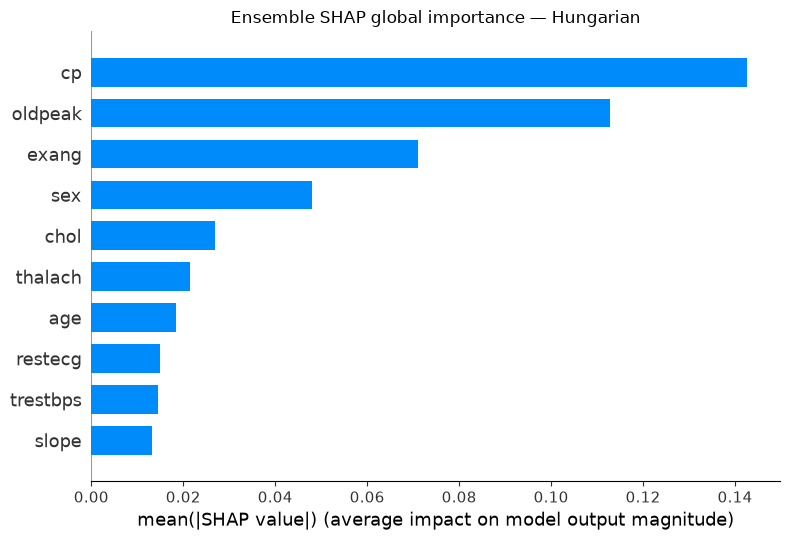

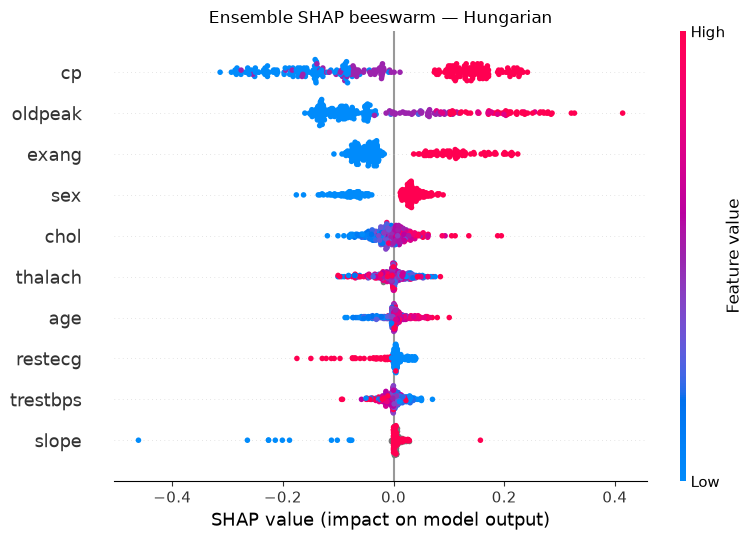


  Top 10 features by mean |SHAP| (ensemble, out-of-fold) — Hungarian
 feature  mean_abs_shap
      cp         0.1426
 oldpeak         0.1128
   exang         0.0709
     sex         0.0481
    chol         0.0270
 thalach         0.0214
     age         0.0183
 restecg         0.0149
trestbps         0.0146
   slope         0.0133

  SHAP (ensemble) — Long Beach VA
    fold 1: resampling=smote_tomek      explained 40 test patients
    fold 2: resampling=smote_tomek      explained 40 test patients
    fold 3: resampling=smote            explained 40 test patients
    fold 4: resampling=borderline_smote explained 40 test patients
    fold 5: resampling=borderline_smote explained 40 test patients
  Saved -> ./heart_disease_revision_results\balanced_accuracy\shap_long_beach_va.pkl


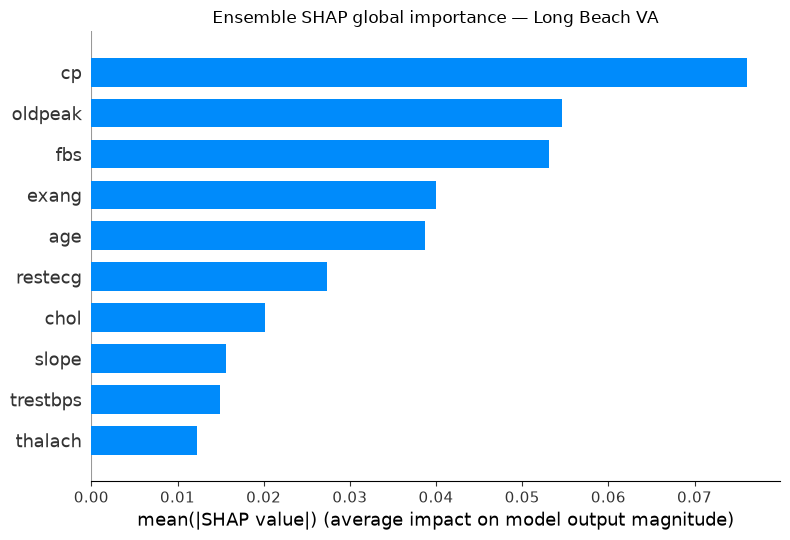

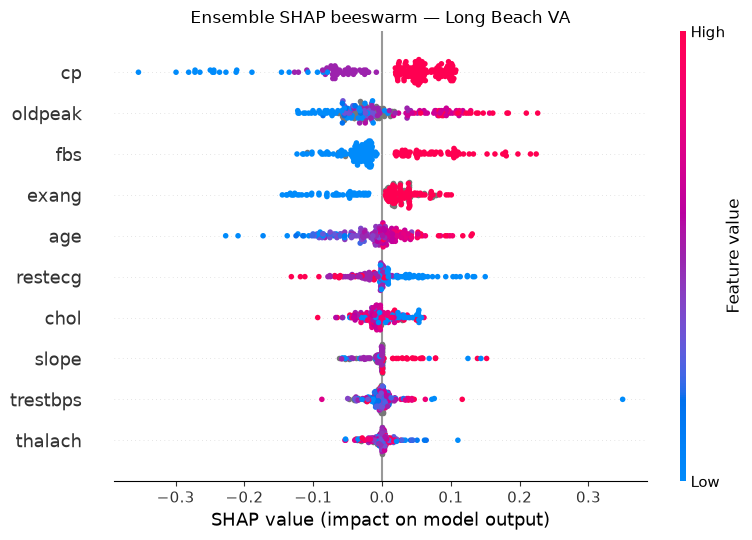


  Top 10 features by mean |SHAP| (ensemble, out-of-fold) — Long Beach VA
 feature  mean_abs_shap
      cp         0.0761
 oldpeak         0.0547
     fbs         0.0531
   exang         0.0400
     age         0.0387
 restecg         0.0274
    chol         0.0202
   slope         0.0156
trestbps         0.0150
 thalach         0.0122

  SHAP (ensemble) — Statlog Heart
    fold 1: resampling=none             explained 54 test patients
    fold 2: resampling=none             explained 54 test patients
    fold 3: resampling=none             explained 54 test patients
    fold 4: resampling=smote            explained 54 test patients
    fold 5: resampling=smote_tomek      explained 54 test patients
  Saved -> ./heart_disease_revision_results\balanced_accuracy\shap_statlog.pkl


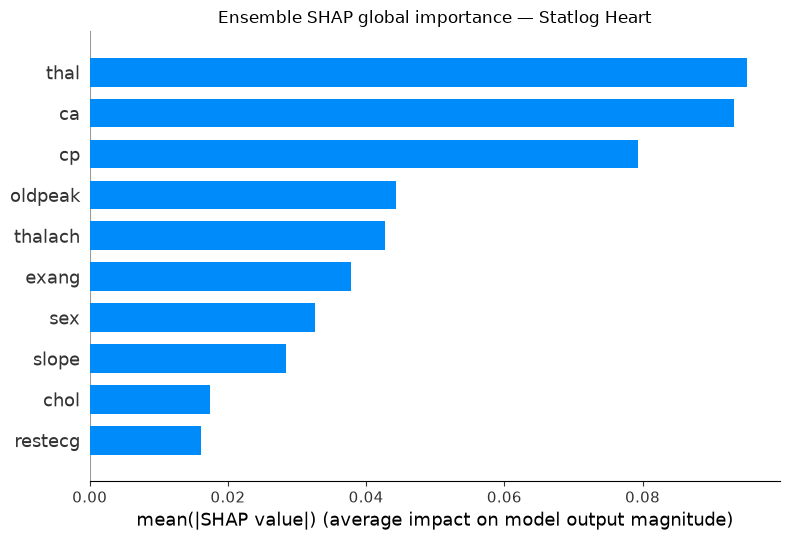

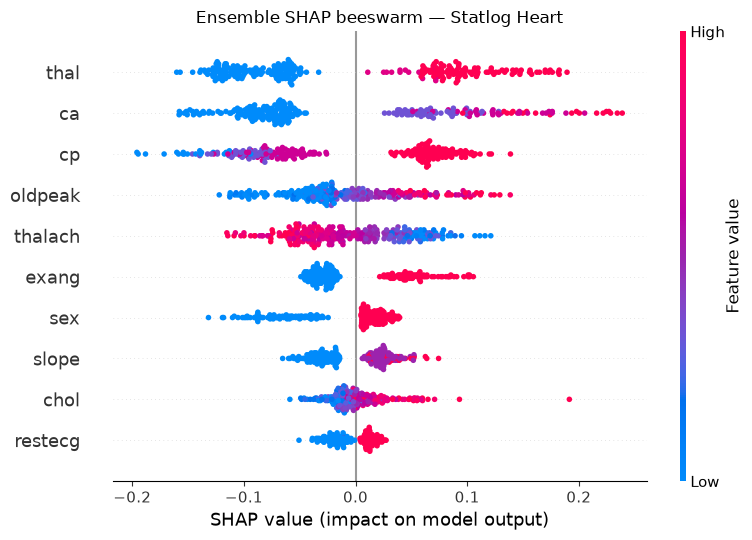


  Top 10 features by mean |SHAP| (ensemble, out-of-fold) — Statlog Heart
feature  mean_abs_shap
   thal         0.0951
     ca         0.0933
     cp         0.0794
oldpeak         0.0443
thalach         0.0428
  exang         0.0378
    sex         0.0327
  slope         0.0284
   chol         0.0175
restecg         0.0161

  SHAP (ensemble) — Cleveland
    fold 1: resampling=none             explained 61 test patients
    fold 2: resampling=smote_tomek      explained 61 test patients
    fold 3: resampling=borderline_smote explained 61 test patients
    fold 4: resampling=smote_tomek      explained 60 test patients
    fold 5: resampling=smote            explained 60 test patients
  Saved -> ./heart_disease_revision_results\balanced_accuracy\shap_cleveland.pkl


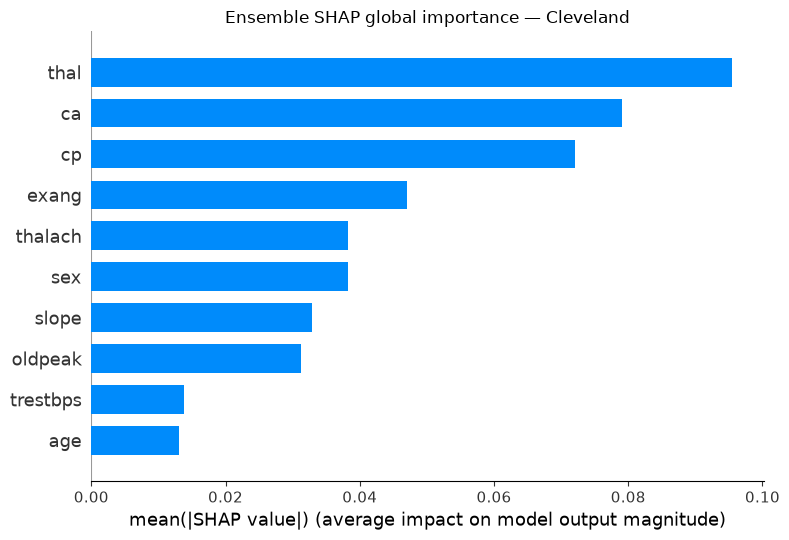

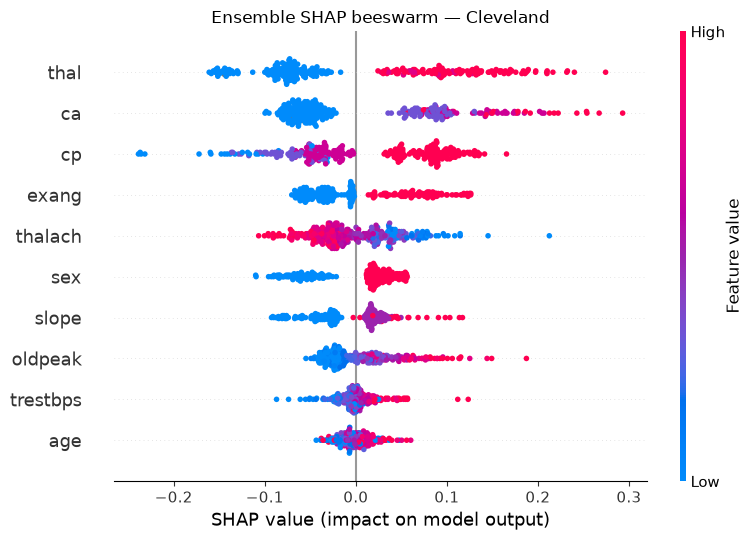


  Top 10 features by mean |SHAP| (ensemble, out-of-fold) — Cleveland
 feature  mean_abs_shap
    thal         0.0954
      ca         0.0791
      cp         0.0721
   exang         0.0471
 thalach         0.0383
     sex         0.0383
   slope         0.0329
 oldpeak         0.0313
trestbps         0.0138
     age         0.0130

  SHAP (ensemble) — Heart Failure Clinical
    fold 1: resampling=smote_tomek      explained 60 test patients
    fold 2: resampling=smote_tomek      explained 60 test patients
    fold 3: resampling=borderline_smote explained 60 test patients
    fold 4: resampling=smote            explained 60 test patients
    fold 5: resampling=smote            explained 59 test patients
  Saved -> ./heart_disease_revision_results\balanced_accuracy\shap_heart_failure.pkl


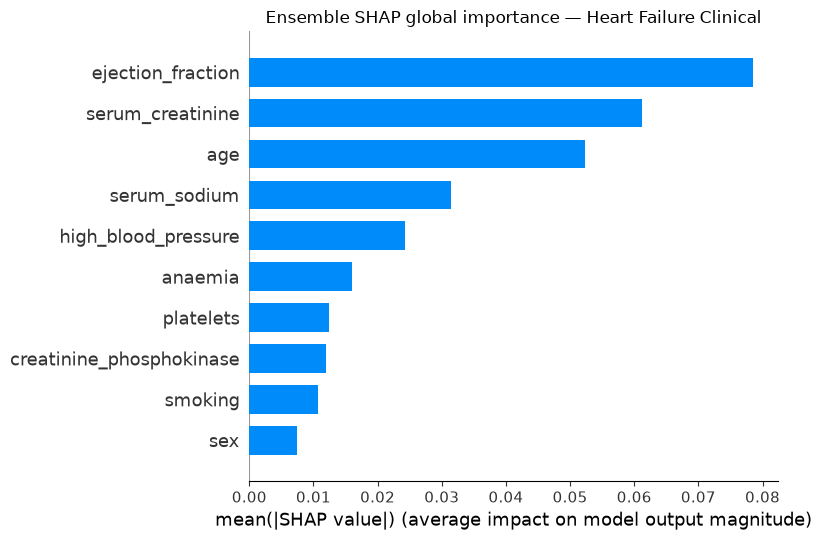

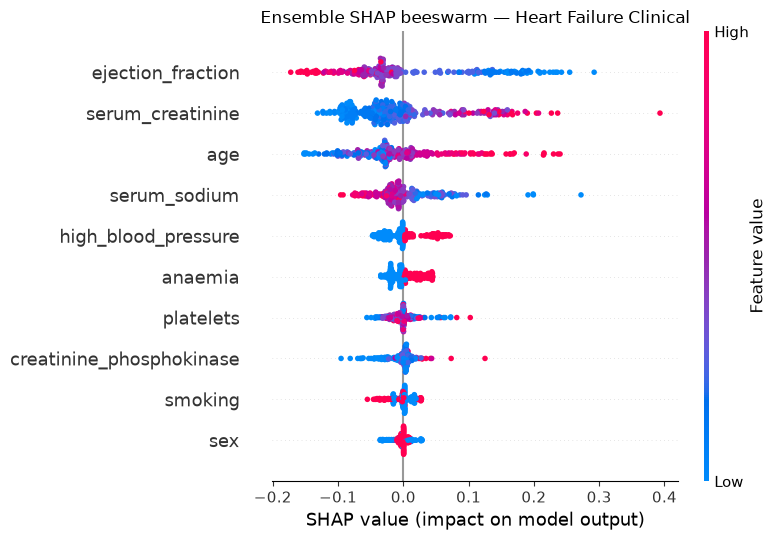


  Top 10 features by mean |SHAP| (ensemble, out-of-fold) — Heart Failure Clinical
                 feature  mean_abs_shap
       ejection_fraction         0.0785
        serum_creatinine         0.0613
                     age         0.0523
            serum_sodium         0.0315
     high_blood_pressure         0.0243
                 anaemia         0.0159
               platelets         0.0124
creatinine_phosphokinase         0.0119
                 smoking         0.0107
                     sex         0.0074

Top-5 features per dataset (ensemble-level SHAP)

   Hungarian Long Beach VA Statlog Heart Cleveland Heart Failure Clinical
#1        cp            cp          thal      thal      ejection_fraction
#2   oldpeak       oldpeak            ca        ca       serum_creatinine
#3     exang           fbs            cp        cp                    age
#4       sex         exang       oldpeak     exang           serum_sodium
#5      chol           age       thalach   thalach    hi

In [ ]:
import shap
import matplotlib.pyplot as plt

SV = 'Soft Voting Ensemble'
SHAP_BACKGROUND = 30          # jumlah sampel background dari outer-training fold
SHAP_PERMUTATIONS = 5         # jumlah permutasi per sampel (max_evals = 2 * n_fitur * permutasi + 1)
SHAP_TOP_N = 10

def prepare_xy(df, target_col, binarize=True, drop_features=None):
    """Persiapan X, y yang sama persis dengan evaluate_dataset."""
    d = df.dropna(subset=[target_col]).copy()
    if binarize:
        d[target_col] = (pd.to_numeric(d[target_col], errors='coerce') > 0).astype(int)
    if drop_features:
        d = d.drop(columns=drop_features)
    X = d.drop(columns=[target_col]).reset_index(drop=True)
    y = pd.Series(d[target_col].astype(int).values)
    return X, y

def ensemble_oof_shap(summary, X, y):
    assert list(X.columns) == summary['features'], 'Kolom tidak sama dengan saat eksperimen'
    fold_info = summary['results'][SV]['fold_info']
    outer_cv = StratifiedKFold(n_splits=N_OUTER_FOLDS, shuffle=True, random_state=RANDOM_STATE)

    shap_vals = np.zeros(X.shape, dtype=float)
    cols = list(X.columns)
    n_feat = len(cols)

    for k, (tr, te) in enumerate(outer_cv.split(X, y)):
        info = fold_info[k]
        svm, rf, lgbm = _base_learners(info['base_params'])
        pipe = _make_pipe(WeightedSoftVoting(svm=svm, rf=rf, lgbm=lgbm, **info['weights']),
                          info['resampling'])
        pipe.fit(X.iloc[tr], y.iloc[tr])

        def f(Z):
            return pipe.predict_proba(pd.DataFrame(Z, columns=cols))[:, 1]

        bg = X.iloc[tr].sample(n=min(SHAP_BACKGROUND, len(tr)), random_state=RANDOM_STATE)
        masker = shap.maskers.Independent(bg.values, max_samples=len(bg))
        explainer = shap.PermutationExplainer(f, masker, seed=RANDOM_STATE)
        ex = explainer(X.iloc[te].values, max_evals=2 * n_feat * SHAP_PERMUTATIONS + 1, silent=True)
        shap_vals[te] = ex.values
        print(f'    fold {k + 1}: resampling={info["resampling"]:<16} explained {len(te)} test patients')

    return shap_vals

def report_shap(name, X, shap_vals, top_n=SHAP_TOP_N):
    fname = name.replace(' ', '_')
    mean_abs = np.abs(shap_vals).mean(axis=0)
    shap_df = (pd.DataFrame({'feature': X.columns, 'mean_abs_shap': mean_abs})
               .sort_values('mean_abs_shap', ascending=False).reset_index(drop=True))

    plt.figure()
    shap.summary_plot(shap_vals, X, plot_type='bar', max_display=top_n, show=False)
    plt.title(f'Ensemble SHAP global importance — {name}')
    plt.tight_layout(); plt.savefig(f'shap_ensemble_bar_{fname}.png', dpi=150, bbox_inches='tight'); plt.show()

    plt.figure()
    shap.summary_plot(shap_vals, X, max_display=top_n, show=False)
    plt.title(f'Ensemble SHAP beeswarm — {name}')
    plt.tight_layout(); plt.savefig(f'shap_ensemble_beeswarm_{fname}.png', dpi=150, bbox_inches='tight'); plt.show()

    print(f'\n  Top {top_n} features by mean |SHAP| (ensemble, out-of-fold) — {name}')
    print(shap_df.head(top_n).round(4).to_string(index=False))
    return shap_df

SHAP_JOBS = [
    ('hungarian',     summary_hungarian, df_hun,       'target',      True,  None),
    ('long_beach_va', summary_va,        df_va,        'target',      True,  None),
    ('statlog',       summary_statlog,   df_stat,      'target',      False, None),
    ('cleveland',     summary_cleveland, df_cleveland, 'target',      True,  None),
    ('heart_failure', summary_hf,        df_hf,        'DEATH_EVENT', False, ['time']),
]

shap_results = {}
for key, summ, df_, tgt, binz, drop in SHAP_JOBS:
    name = summ['dataset']
    print('\n' + '=' * 72 + f'\n  SHAP (ensemble) — {name}\n' + '=' * 72)
    X, y = prepare_xy(df_, tgt, binarize=binz, drop_features=drop)

    cache = f'shap_{key}'
    path = os.path.join(RESULTS_PATH, f'{cache}.pkl')
    if os.path.exists(path) and not FORCE_RERUN:
        shap_vals = load_summary(cache)
        print(f'  Loaded SHAP values from {path}')
    else:
        shap_vals = ensemble_oof_shap(summ, X, y)
        save_summary(shap_vals, cache)

    shap_results[name] = report_shap(name, X, shap_vals)

# Ringkasan 5 fitur teratas per dataset (pengganti Table 7)
top5 = pd.DataFrame({name: df.head(5)['feature'].tolist() for name, df in shap_results.items()},
                    index=[f'#{i}' for i in range(1, 6)])
print('\nTop-5 features per dataset (ensemble-level SHAP)\n')
print(top5.to_string())
save_summary(shap_results, 'shap_ensemble_rankings')

In [ ]:
# [REV] Mean ± SD semua metrik (SD = standar deviasi sampel antar 5 outer fold, ddof=1)
import os
import numpy as np
import pandas as pd

SD_METRICS = [('balanced_acc', 'BalAcc', 100), ('accuracy', 'Acc', 100),
              ('specificity', 'Spec', 100), ('recall', 'Rec', 100),
              ('f1', 'F1', 100), ('mcc', 'MCC', 1), ('roc_auc', 'AUC', 100)]
DDOF = 1

def _fmt(mean, sd, scale):
    return f'{mean:.3f} ± {sd:.3f}' if scale == 1 else f'{mean:.2f} ± {sd:.2f}'

def _folds(s, m, key, scale):
    return np.asarray(s['results'][m][key], dtype=float) * scale

# Pastikan variabel eksperimen tersedia
if 'all_summaries' not in globals() or 'MODEL_ORDER' not in globals():
    raise NameError("Variabel 'all_summaries' atau 'MODEL_ORDER' belum terdefinisi. Silakan jalankan sel hasil eksperimen di atas terlebih dahulu!")

# [A] Per dataset: mean ± SD antar 5 outer fold (untuk Table 8, Table 9, dan tabel per dataset)
per_ds = {}
for s in all_summaries:
    rows = {}
    for m in MODEL_ORDER:
        rows[m] = {lab: _fmt(_folds(s, m, k, sc).mean(), _folds(s, m, k, sc).std(ddof=DDOF), sc)
                   for k, lab, sc in SD_METRICS}
    per_ds[s['dataset']] = pd.DataFrame(rows).T
    print(f"\n[A] {s['dataset']} — mean ± SD over {N_OUTER_FOLDS} outer folds (ddof={DDOF})")
    print(per_ds[s['dataset']].to_string())

# [B] Ringkasan diagnosis (Table 5): mean atas 4 dataset
#     SD_folds   = SD atas 20 outer fold gabungan (ikut menangkap selisih antar dataset)
#     SD_dataset = SD atas 4 rata-rata dataset
diag_s = [s for s in all_summaries if s['task'] == 'diagnosis']
rows_f, rows_d = {}, {}
for m in MODEL_ORDER:
    rf, rd = {}, {}
    for k, lab, sc in SD_METRICS:
        pooled = np.concatenate([_folds(s, m, k, sc) for s in diag_s])
        ds_means = np.array([_folds(s, m, k, sc).mean() for s in diag_s])
        rf[lab] = _fmt(ds_means.mean(), pooled.std(ddof=DDOF), sc)
        rd[lab] = _fmt(ds_means.mean(), ds_means.std(ddof=DDOF), sc)
    rows_f[m], rows_d[m] = rf, rd
tab5_folds = pd.DataFrame(rows_f).T
tab5_ds = pd.DataFrame(rows_d).T
print('\n[B1] Diagnosis mean ± SD over 20 pooled outer folds')
print(tab5_folds.to_string())
print('\n[B2] Diagnosis mean ± SD over the 4 dataset means')
print(tab5_ds.to_string())

# Simpan ke CSV agar mudah disalin ke Word
out_dir = RESULTS_PATH
for name, df_ in per_ds.items():
    df_.to_csv(os.path.join(out_dir, f"meanSD_{name.replace(' ', '_')}.csv"), encoding='utf-8-sig')
tab5_folds.to_csv(os.path.join(out_dir, 'meanSD_diagnosis_pooled20folds.csv'), encoding='utf-8-sig')
tab5_ds.to_csv(os.path.join(out_dir, 'meanSD_diagnosis_4datasets.csv'), encoding='utf-8-sig')
print('\nCSV saved to', os.path.abspath(out_dir))


[A] Hungarian — mean ± SD over 5 outer folds (ddof=1)
                            BalAcc            Acc           Spec            Rec             F1            MCC           AUC
SVM                   81.04 ± 4.91   80.97 ± 5.22   80.87 ± 6.58   81.21 ± 5.31   75.64 ± 5.80  0.607 ± 0.101  88.35 ± 1.68
Naive Bayes           78.29 ± 7.90  77.24 ± 11.04  74.54 ± 19.44   82.03 ± 7.16   73.18 ± 8.50  0.563 ± 0.153  88.36 ± 1.76
Random Forest         79.08 ± 6.01   80.97 ± 5.49   85.60 ± 6.80  72.55 ± 10.51   73.23 ± 8.03  0.588 ± 0.120  88.36 ± 2.89
J48 (DecTree)         73.81 ± 6.06   75.16 ± 4.49   78.75 ± 4.03  68.87 ± 12.83   66.28 ± 7.74  0.471 ± 0.109  78.15 ± 7.40
Logistic Regression   82.14 ± 5.12   84.03 ± 5.12   88.82 ± 5.83   75.45 ± 6.27   77.41 ± 6.78  0.652 ± 0.109  89.87 ± 2.04
XGBoost               77.88 ± 5.82   79.95 ± 5.21   85.06 ± 7.36  70.69 ± 11.51   71.58 ± 7.94  0.566 ± 0.111  87.31 ± 3.17
LightGBM              78.16 ± 8.00   79.96 ± 7.66   84.58 ± 6.88   71.73 ± 9.